# Deepfake Recognition · FF++ data audit and EDA (Colab)
IS 665 · Team 6 · Interim Progress Report

This notebook loads FaceForensics++ (c23 videos), checks data quality and leakage, creates the EDA figures and runs the first baselines (B0 majority class, B1 logistic regression on temporal features). Its outputs are the numbers and figures for the report.

**Data source.** The official FF++ download servers (TUM/SFU) were unreachable (connection refused on all three servers). As a temporary substitute we use the Kaggle re-upload `xdxd003/ff-c23` (same c23 videos). Cell 9 checks the mirror against the official file list. As soon as the official servers are back, set `DATA_SOURCE = "official"` and run everything again. **State this in the report.**

**Run the cells from top to bottom.** Settings are in cell 1.

**Terms of Use:** FF++ data may only be used for research and must not be shared. Do not upload videos to the repository.

In [1]:
#@title 1 · Settings
#@markdown Where the data comes from:
DATA_SOURCE = "kaggle"  #@param ["kaggle", "official"]
KAGGLE_DATASET = "xdxd003/ff-c23"  #@param {type:"string"}
DRIVE_DIR = "/content/drive/MyDrive/IS665_Deepfake"  #@param {type:"string"}
#@markdown Use all 1,000 original videos? (needed for the leakage check)
ALL_ORIGINALS = False  #@param {type:"boolean"}
#@markdown Fake videos per method (0 = all 1,000; 250 per method gives 1,000 real vs. 1,000 fake):
N_FAKES_PER_METHOD = 250  #@param {type:"integer"}
#@markdown Only for DATA_SOURCE = "official":
SCRIPT_URL = ""  #@param {type:"string"}
I_AGREE_FF_TERMS = True  #@param {type:"boolean"}

METHODS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]
METHODS_STR = " ".join(METHODS)
LIMIT_ORIG = 0 if ALL_ORIGINALS else N_FAKES_PER_METHOD
DATA_DIR = f"{DRIVE_DIR}/ffpp"            # official download target (replaced by the Kaggle path in cell 3K)
OUT_DIR  = f"{DRIVE_DIR}/eda_out"         # results: CSV, JSON, figures (saved in Drive)
SCRIPT   = f"{DRIVE_DIR}/faceforensics_download_v4.py"
META_DIR = "/content/FaceForensics/dataset"   # official splits from GitHub

In [2]:
#@title 2 · Mount Drive and check libraries
from google.colab import drive
drive.mount("/content/drive")

import os, sys, json, subprocess, glob, random
from pathlib import Path
os.makedirs(OUT_DIR, exist_ok=True)

import cv2
print("OpenCV", cv2.__version__)
if not hasattr(cv2, "CascadeClassifier"):
    !pip -q install "opencv-python-headless<5"
    print("OpenCV 4 installed -> Runtime > Restart session, then run again from cell 1.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OpenCV 4.14.0


In [3]:
#@title 3K · Load Kaggle mirror
if DATA_SOURCE != "kaggle":
    print("Skipped: DATA_SOURCE is 'official'.")
else:
    !pip -q install -U kagglehub
    try:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        print("Kaggle login from Colab secrets.")
    except Exception:
        print("No Kaggle secrets found - trying without login.")
    import kagglehub
    DATA_DIR = kagglehub.dataset_download(KAGGLE_DATASET)   # downloads into the Colab runtime (not Drive)
    print("Data in:", DATA_DIR)

    # show the folder structure (folders with the number of .mp4 files)
    for root, dirs, files in sorted(os.walk(DATA_DIR)):
        depth = Path(root).relative_to(DATA_DIR).parts
        n = sum(f.endswith(".mp4") for f in files)
        if len(depth) <= 4 and (n or dirs):
            print("  " * len(depth) + (Path(root).name or "/") + (f"  [{n} mp4]" if n else ""))
    other = [f for _, _, fs in os.walk(DATA_DIR) for f in fs if not f.endswith(".mp4")]
    print("Other files (e.g. CSV):", other[:10])

No Kaggle secrets found - trying without login.


100%|██████████| 16.7G/16.7G [03:36<00:00, 82.7MB/s]

Extracting files...


Data in: /root/.cache/kagglehub/datasets/xdxd003/ff-c23/versions/1
1
  FaceForensics++_C23
    DeepFakeDetection  [1000 mp4]
    Deepfakes  [1000 mp4]
    Face2Face  [1000 mp4]
    FaceShifter  [1000 mp4]
    FaceSwap  [1000 mp4]
    NeuralTextures  [1000 mp4]
    original  [1000 mp4]
Other files (e.g. CSV): ['DeepFakeDetection.csv', 'FaceShifter.csv', 'FaceSwap.csv', 'FF++_Metadata_Shuffled.csv', 'Mean_Data.csv', 'NeuralTextures.csv', 'FF++_Metadata.csv', 'original.csv', 'Deepfakes.csv', 'Face2Face.csv']


## Data source B: official download (only if `DATA_SOURCE = "official"`)

In [ ]:
#@title 3 · Get the official download script
#@markdown If you have the script as a file on your computer, tick the box: an upload dialog will open.
UPLOAD_FROM_COMPUTER = False  #@param {type:"boolean"}
if DATA_SOURCE != "official":
    print("Skipped: DATA_SOURCE is 'kaggle' (see cell 3K).")
else:
    import socket
    from urllib.parse import urlparse
    os.makedirs(DATA_DIR, exist_ok=True)

    def diagnose(url):
        host = urlparse(url).hostname
        if not host:
            return f"'{url}' is not a valid URL (it must start with http://)."
        try:
            ip = socket.gethostbyname(host)
        except socket.gaierror as e:
            return f"DNS: hostname '{host}' cannot be resolved ({e})."
        r = subprocess.run(["wget", "-S", "--spider", "-T", "20", "-t", "1", url], capture_output=True, text=True)
        status = [l.strip() for l in r.stderr.splitlines() if "HTTP/" in l]
        return f"{host} -> {ip}; server response: {status[-1] if status else 'no response (timeout/refused)'}"

    if os.path.exists(SCRIPT) and os.path.getsize(SCRIPT) > 1000:
        print("Script found in Drive:", SCRIPT)
    elif UPLOAD_FROM_COMPUTER:
        from google.colab import files
        up = files.upload()
        name = next(iter(up))
        with open(SCRIPT, "wb") as f:
            f.write(up[name])
        print(f"'{name}' uploaded and saved as {SCRIPT}")
    elif not SCRIPT_URL.strip():
        print("SCRIPT_URL is empty. Enter the link in cell 1 and run cell 1 again, or tick UPLOAD_FROM_COMPUTER.")
    else:
        url = SCRIPT_URL.strip()
        print("Diagnosis:", diagnose(url))
        r = subprocess.run(["wget", "-T", "30", "-t", "2", "-O", SCRIPT, url], capture_output=True, text=True)
        if r.returncode == 0 and os.path.getsize(SCRIPT) > 1000:
            print("Script downloaded and saved in Drive:", SCRIPT)
        else:
            if os.path.exists(SCRIPT):
                os.remove(SCRIPT)
            print(r.stderr[-800:], "\nDownload of the script failed.")

In [ ]:
#@title 5 · Official download (c23 videos)
if DATA_SOURCE != "official":
    print("Skipped: DATA_SOURCE is 'kaggle' (see cell 3K).")
else:
    assert I_AGREE_FF_TERMS, "Please confirm in cell 1 that you agreed to the Terms of Use."
    for host in ["http://canis.vc.in.tum.de:8100/v3/misc/filelist.json", "http://falas.cmpt.sfu.ca:8100/v3/misc/filelist.json"]:
        r = subprocess.run(["curl", "-s", "-m", "15", "-o", "/dev/null", "-w", "%{http_code}", host], capture_output=True, text=True)
        print("Server check", host.split("/")[2], "->", r.stdout)

    def ff_download(dataset, n=0):
        for server in ["EU", "EU2", "CA"]:
            cmd = [sys.executable, SCRIPT, DATA_DIR, "-d", dataset, "-c", "c23", "-t", "videos", "--server", server]
            if n:
                cmd += ["--num_videos", str(n)]
            print(f"\n=== {dataset} (server {server}) ===")
            p = subprocess.Popen(cmd, stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
            p.stdin.write("\n"); p.stdin.flush(); p.stdin.close()   # confirms the ToS prompt (agreed above)
            last = []
            for line in p.stdout:
                last = (last + [line.rstrip()])[-5:]
                if "Downloading" in line or "rror" in line:
                    print(line.rstrip())
            if p.wait() == 0:
                return True
            print("\n".join(last), f"\n-> server {server} failed, trying the next one")
        return False

    status = {"original": ff_download("original", LIMIT_ORIG)}
    for m in METHODS:
        status[m] = ff_download(m, N_FAKES_PER_METHOD)
    print("\nStatus:", status)

## Analysis

In [4]:
#@title 4 · Official split files from GitHub
if not os.path.exists(META_DIR):
    !git clone -q --depth 1 https://github.com/ondyari/FaceForensics.git /content/FaceForensics
print(sorted(os.listdir(f"{META_DIR}/splits")), os.path.exists(f"{META_DIR}/conversion_dict.json"))

['test.json', 'train.json', 'val.json'] True


In [5]:
%%writefile /content/ff_eda.py
#!/usr/bin/env python3
"""
FaceForensics++ data audit, EDA and preliminary baselines (Interim Progress Report).

Fills the numbers and figures marked [TODO] in the report draft.

Layout: found automatically. Works with the official download layout
  <FF_ROOT>/original_sequences/youtube/c23/videos/000.mp4
  <FF_ROOT>/manipulated_sequences/<Method>/c23/videos/000_003.mp4
and with mirrors that use other folder names (method taken from the folder name,
original vs. fake from the file name 000.mp4 / 000_003.mp4).
Official split files + conversion_dict.json come from the FaceForensics GitHub repo
(dataset/splits/{train,val,test}.json, dataset/conversion_dict.json).

Usage:
  python ff_eda.py --ff_root /data/ff++ --meta_dir FaceForensics/dataset --out out \
      [--methods Deepfakes Face2Face FaceSwap NeuralTextures] [--clips 2 --clip_len 16]
      [--limit 50]   # quick test on a few videos per method

Outputs (in --out): manifest.csv, clips.csv, quality_report.json, baseline_results.json,
fig1_class_split.png, fig2_video_properties.png, fig3_temporal_instability.png,
fig4_example_crops.png
"""
import argparse, collections, hashlib, json, os, re, sys
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, accuracy_score)

DEFAULT_METHODS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]
# fixed categorical order (colorblind-validated palette), colour follows the entity
COLORS = {"original": "#2a78d6", "Deepfakes": "#eb6834", "Face2Face": "#1baf7a",
          "FaceSwap": "#eda100", "NeuralTextures": "#e87ba4", "FaceShifter": "#008300"}
SEED = 665
FEATURES = ["diff_mean", "diff_std", "diff_max", "diff_p95_ratio", "sharp_mean",
            "sharp_std", "face_rate"]
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "figure.dpi": 150})


# ----------------------------------------------------------------------------- manifest
def load_splits(meta_dir):
    split_of = {}
    for s in ("train", "val", "test"):
        for a, b in json.load(open(Path(meta_dir) / "splits" / f"{s}.json")):
            split_of[a] = s
            split_of[b] = s
    conv = json.load(open(Path(meta_dir) / "conversion_dict.json"))
    yt_of = {k: v.split()[0] for k, v in conv.items()}
    return split_of, yt_of


ID_RE = re.compile(r"^(\d{3})(?:_(\d{3}))?$")
ORIGINAL_ALIASES = ("original", "youtube", "real", "pristine")
SKIP_PARTS = ("deepfakedetection", "actors", "dfd")


def classify(path, root, methods, comp):
    """Return (method, target, source) for a video path, or (None, reason, None).
    Works for the official layout and for re-uploads/mirrors with other folder names."""
    parts = [x.lower() for x in path.relative_to(root).parts[:-1]]   # relative: root folder names must not count
    joined = "/".join(parts)
    m = ID_RE.match(path.stem)
    if not m:
        return None, "filename not FF++ style", None
    if any(k in joined for k in SKIP_PARTS):
        return None, "DeepFakeDetection subset (not used)", None
    other_comp = {"c0", "raw", "c23", "c40"} - {comp}
    if any(p in other_comp for p in parts):
        return None, "other compression level", None
    target, source = m.group(1), m.group(2)
    method = next((mm for mm in methods if mm.lower() in joined), None)
    if source is None:
        if method is None and any(a in joined for a in ORIGINAL_ALIASES):
            return "original", target, None
        if method is None:
            return "original", target, None      # NNN.mp4 outside any method folder
        return None, "single id inside a method folder", None
    if method is None:
        return None, "pair id but method not recognised from folder name", None
    return method, target, source


def build_manifest(ff_root, methods, comp, split_of, yt_of, limit, limit_original=0):
    """Scan ff_root recursively; classify every .mp4. limit = max fakes per method,
    limit_original = max originals (0 = all)."""
    found, skipped = collections.defaultdict(list), collections.Counter()
    for p in sorted(Path(ff_root).rglob("*.mp4")):
        method, a, b = classify(p, Path(ff_root), methods, comp)
        if method is None:
            skipped[a] += 1
        else:
            found[method].append((p, a, b))
    rows = []
    for method, items in found.items():
        cap = limit_original if method == "original" else limit
        seen = set()
        for p, target, source in items:
            key = p.stem
            if key in seen:          # same file present twice in the upload
                skipped["duplicate filename across folders"] += 1
                continue
            seen.add(key)
            if cap and len(seen) > cap:
                break
            rows.append(dict(video_id=key if method == "original" else f"{method}/{key}",
                             path=str(p), method=method, label=int(method != "original"),
                             target_id=target, source_id=source,
                             split=split_of.get(target), source_split=split_of.get(source) if source else None,
                             youtube_id=yt_of.get(target)))
    man = pd.DataFrame(rows)
    man.attrs["skipped"] = dict(skipped)
    return man


def completeness_vs_official(man, meta_dir, methods):
    """Compare the files present with the official FF++ file list (from the split files):
    1,000 originals and 1,000 fakes per method named target_source in both directions."""
    pairs = [p for s in ("train", "val", "test") for p in json.load(open(Path(meta_dir) / "splits" / f"{s}.json"))]
    expected = {"original": {x for p in pairs for x in p}}
    for m in methods:
        expected[m] = {f"{a}_{b}" for a, b in pairs} | {f"{b}_{a}" for a, b in pairs}
    out = {}
    for m, exp in expected.items():
        have = set(man.loc[man.method == m, "video_id"].str.split("/").str[-1])
        out[m] = dict(expected=len(exp), present=len(have & exp), not_in_official_list=len(have - exp))
    return out


def flag_cross_split_sources(man, split_of, yt_of):
    """Some FF++ sequences were cut from the same YouTube video (977 sources -> 1,000 ids).
    If such a group spans splits, the same person/scene is in train and val/test.
    We keep the train copy and exclude the val/test id plus every fake that uses it
    as target or source."""
    groups = collections.defaultdict(list)
    for vid, y in yt_of.items():
        groups[y].append(vid)
    bad = set()
    for ids in groups.values():
        if len({split_of.get(i) for i in ids}) > 1:
            bad |= {i for i in ids if split_of.get(i) in ("val", "test")}
    man["leak_excluded"] = man.target_id.isin(bad) | man.source_id.isin(bad)
    return man, sorted(bad)


# ----------------------------------------------------------------------------- per video
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


def dhash(gray, size=8):
    g = cv2.resize(gray, (size + 1, size))
    bits = (g[:, 1:] > g[:, :-1]).flatten()
    return "".join("1" if b else "0" for b in bits)


if not hasattr(cv2, "CascadeClassifier"):
    sys.exit("This OpenCV build has no Haar cascades (OpenCV 5 removed them). "
             "Install OpenCV 4.x:  pip install 'opencv-python<5'")
_CASCADE = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")


def detect_face(gray):
    faces = _CASCADE.detectMultiScale(gray, 1.1, 5, minSize=(40, 40))
    if len(faces) == 0:
        return None, 0
    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])  # largest face = main face
    return (x, y, w, h), len(faces)


def expand_box(box, W, H, scale=1.3):
    x, y, w, h = box
    cx, cy, s = x + w / 2, y + h / 2, max(w, h) * scale
    x0, y0 = int(max(0, cx - s / 2)), int(max(0, cy - s / 2))
    x1, y1 = int(min(W, cx + s / 2)), int(min(H, cy + s / 2))
    return x0, y0, x1, y1


def analyse_video(path, n_clips, clip_len, crop=112):
    """Video metadata + clip-level temporal features.
    One face box per clip (detected on the clip's first frame) is held fixed for all
    frames of the clip, so frame-to-frame differences reflect what changes inside
    the face region (manipulation flicker, motion) and not jitter of our own cropper."""
    info = dict(readable=False, n_frames=0, fps=np.nan, width=np.nan, height=np.nan,
                duration_s=np.nan, file_mb=os.path.getsize(path) / 1e6, sha256=sha256(path),
                dhash_mid=None, multi_face_rate=np.nan)
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        return info, [], None
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    info.update(readable=n > 0, n_frames=n, fps=fps, width=W, height=H,
                duration_s=n / fps if fps else np.nan)
    if n < clip_len:
        cap.release()
        return info, [], None
    starts = np.linspace(0, n - clip_len, n_clips + 2)[1:-1].astype(int) if n_clips > 1 else [ (n - clip_len) // 2 ]
    clips, example, multi = [], None, []
    for ci, st in enumerate(starts):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(st))
        frames = []
        for _ in range(clip_len):
            ok, fr = cap.read()
            if not ok:
                break
            frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY))
        if len(frames) < clip_len:
            continue
        if ci == len(starts) // 2:
            info["dhash_mid"] = dhash(frames[0])
        box, nf = detect_face(frames[0])
        multi.append(nf > 1)
        found = sum(detect_face(f)[0] is not None for f in frames[:: max(1, clip_len // 4)])
        face_rate = found / len(frames[:: max(1, clip_len // 4)])
        if box is None:
            clips.append(dict(clip=ci, start=int(st), face_found=0, face_rate=face_rate))
            continue
        x0, y0, x1, y1 = expand_box(box, W, H)
        crops = np.stack([cv2.resize(f[y0:y1, x0:x1], (crop, crop)) for f in frames]).astype(np.float32)
        d = np.abs(np.diff(crops, axis=0)).mean(axis=(1, 2))            # per transition
        sharp = np.array([cv2.Laplacian(c, cv2.CV_32F).var() for c in crops])
        clips.append(dict(clip=ci, start=int(st), face_found=1, face_rate=face_rate,
                          diff_mean=d.mean(), diff_std=d.std(), diff_max=d.max(),
                          diff_p95_ratio=np.percentile(d, 95) / (np.median(d) + 1.0),  # +1 grey level keeps static clips stable
                          sharp_mean=sharp.mean(), sharp_std=sharp.std()))
        if example is None:
            example = crops[0].astype(np.uint8)
    cap.release()
    info["multi_face_rate"] = float(np.mean(multi)) if multi else np.nan
    return info, clips, example


# ----------------------------------------------------------------------------- quality
def quality_report(man, clips):
    q = {}
    q["n_videos"] = int(len(man))
    q["per_method"] = man.method.value_counts().to_dict()
    q["unreadable_videos"] = int((~man.readable).sum())
    q["too_short_for_clip"] = int((man.n_frames < man.attrs.get("clip_len", 16)).sum())
    q["missing_split_assignment"] = int(man.split.isna().sum())
    fake = man[man.label == 1]
    q["fake_source_split_mismatch"] = int((fake.split != fake.source_split).sum())
    q["exact_duplicate_files"] = int(man.duplicated("sha256", keep=False).sum())
    # near-duplicates across *different* target ids (same id is expected by design: real + its fakes)
    nd = man.dropna(subset=["dhash_mid"]).groupby("dhash_mid").target_id.nunique()
    q["near_duplicate_groups_across_targets"] = int((nd > 1).sum())
    # identity / source-video leakage across official splits
    yt = man[man.method == "original"].groupby("youtube_id").split.nunique()
    q["youtube_sources_spanning_splits"] = int((yt > 1).sum())
    q["fps_values"] = man.fps.round(2).value_counts().head(10).to_dict()
    q["resolution_values"] = (man.width.astype("Int64").astype(str) + "x" +
                              man.height.astype("Int64").astype(str)).value_counts().head(10).to_dict()
    q["frames_quartiles"] = man.n_frames.describe().round(1).to_dict()
    q["frames_iqr_outliers"] = int(iqr_outliers(man.n_frames).sum())
    q["clip_face_found_rate"] = float(clips.face_found.mean()) if len(clips) else None
    q["clip_face_found_rate_by_method"] = (clips.merge(man[["video_id", "method"]])
                                           .groupby("method").face_found.mean().round(3).to_dict()
                                           if len(clips) else {})
    q["multi_face_video_rate"] = float(man.multi_face_rate.mean())
    q["class_ratio_real_to_fake"] = f"1:{(man.label == 1).sum() / max(1, (man.label == 0).sum()):.2f}"
    q["split_counts"] = man.groupby(["split", "method"]).size().unstack(fill_value=0).to_dict("index")
    # shortcut check: do trivial file properties differ by class?
    q["file_property_by_class"] = man.groupby("label")[["file_mb", "n_frames", "width"]].median().round(2).to_dict("index")
    return q


def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    return (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))


# ----------------------------------------------------------------------------- figures
def order(methods):
    return ["original"] + [m for m in methods if m != "original"]


def fig_class_split(man, out):
    ct = man.groupby(["split", "method"]).size().unstack(fill_value=0)
    ct = ct.reindex(["train", "val", "test"]).fillna(0)[[m for m in order(man.method.unique()) if m in ct]]
    fig, ax = plt.subplots(figsize=(7, 3.6))
    x = np.arange(len(ct.index)); w = 0.8 / len(ct.columns)
    for i, m in enumerate(ct.columns):
        b = ax.bar(x + i * w - 0.4 + w / 2, ct[m], w * 0.92, color=COLORS.get(m, "#888"), label=m)
    ax.set_xticks(x, ct.index)
    ax.set_ylabel("Number of videos")
    ax.legend(frameon=False, ncol=len(ct.columns), fontsize=8, loc="lower center", bbox_to_anchor=(.5, 1.0))
    ax.set_title("Figure 1. Videos per class and method in each official split", pad=28)
    ax.grid(axis="y", alpha=.25)
    fig.tight_layout(); fig.savefig(out / "fig1_class_split.png"); plt.close(fig)


def fig_video_properties(man, out):
    meths = order(man.method.unique())
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    for ax, col, lab in [(axes[0], "duration_s", "Duration (s)"), (axes[1], "file_mb", "File size (MB)")]:
        data = [man.loc[man.method == m, col].dropna() for m in meths]
        bp = ax.boxplot(data, patch_artist=True, widths=.6, showfliers=True, medianprops=dict(color="#0b0b0b"),
                        flierprops=dict(markersize=3, alpha=.5))
        for p, m in zip(bp["boxes"], meths):
            p.set_facecolor(COLORS.get(m, "#888")); p.set_alpha(.75)
        ax.set_xticks(range(1, len(meths) + 1), meths, rotation=25, ha="right", fontsize=8)
        ax.set_ylabel(lab); ax.grid(axis="y", alpha=.25)
    fig.suptitle("Figure 2. Video length and file size by class/method (shortcut check)", fontweight="bold")
    fig.tight_layout(); fig.savefig(out / "fig2_video_properties.png"); plt.close(fig)


def fig_temporal(clips, man, out):
    c = clips[clips.face_found == 1].merge(man[["video_id", "method"]])
    meths = [m for m in order(man.method.unique()) if m in set(c.method)]
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    for ax, col, lab in [(axes[0], "diff_mean", "Mean |frame t+1 − frame t| in face crop"),
                         (axes[1], "diff_p95_ratio", "Spikiness of transitions (p95 / median)")]:
        data = [c.loc[c.method == m, col].dropna() for m in meths]
        bp = ax.boxplot(data, patch_artist=True, widths=.6, showfliers=False, medianprops=dict(color="#0b0b0b"))
        for p, m in zip(bp["boxes"], meths):
            p.set_facecolor(COLORS.get(m, "#888")); p.set_alpha(.75)
        ax.set_xticks(range(1, len(meths) + 1), meths, rotation=25, ha="right", fontsize=8)
        ax.set_ylabel(lab, fontsize=9); ax.grid(axis="y", alpha=.25)
    fig.suptitle("Figure 3. Frame-to-frame change inside the face region (clip level)", fontweight="bold")
    fig.tight_layout(); fig.savefig(out / "fig3_temporal_instability.png"); plt.close(fig)


def fig_examples(examples, out, per_method=4):
    meths = [m for m in order(list(examples)) if examples.get(m)]
    if not meths:
        return
    fig, axes = plt.subplots(len(meths), per_method, figsize=(per_method * 1.6, len(meths) * 1.7))
    axes = np.atleast_2d(axes)
    for r, m in enumerate(meths):
        for k in range(per_method):
            ax = axes[r, k]; ax.axis("off")
            if k < len(examples[m]):
                ax.imshow(examples[m][k], cmap="gray")
            if k == 0:
                ax.set_title(m, fontsize=8, loc="left")
    fig.suptitle("Figure 4. Sample face crops after detection and cropping", fontweight="bold", fontsize=10)
    fig.tight_layout(); fig.savefig(out / "fig4_example_crops.png"); plt.close(fig)


# ----------------------------------------------------------------------------- baselines
def metrics(y, pred, score=None):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    r = dict(n=int(len(y)), accuracy=accuracy_score(y, pred),
             precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred, zero_division=0),
             fpr=fp / (fp + tn) if fp + tn else np.nan, f1=f1_score(y, pred, zero_division=0),
             tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))
    if score is not None and len(set(y)) == 2:
        r.update(roc_auc=roc_auc_score(y, score), pr_auc=average_precision_score(y, score))
    return {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in r.items()}


def baselines(man, clips, eval_split="val"):
    res = {"eval_split": eval_split}
    tr, ev = man[man.split == "train"], man[man.split == eval_split]
    if len(ev) == 0 or len(tr) == 0:
        return {"error": "train or eval split empty"}
    # B0: majority class (learned on train)
    maj = int(tr.label.mean() >= 0.5)
    res["B0_majority_video"] = metrics(ev.label.values, np.full(len(ev), maj), np.full(len(ev), float(maj)))
    res["B0_majority_class"] = "fake" if maj else "real"
    # B1: logistic regression on hand-crafted temporal + sharpness features (clip level)
    c = clips[clips.face_found == 1].merge(man[["video_id", "split", "label", "method"]])
    ctr, cev = c[c.split == "train"].dropna(subset=FEATURES), c[c.split == eval_split].dropna(subset=FEATURES)
    if ctr.label.nunique() < 2 or len(cev) == 0:
        res["B1"] = "not enough clips with faces in both classes"
        return res
    # scaler is fit inside the pipeline on TRAIN only -> no leakage of eval statistics
    model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED))
    model.fit(ctr[FEATURES], ctr.label)
    p = model.predict_proba(cev[FEATURES])[:, 1]
    res["B1_logreg_clip"] = metrics(cev.label.values, (p >= .5).astype(int), p)
    cev = cev.assign(p=p)
    v = cev.groupby("video_id").agg(label=("label", "first"), p=("p", "mean"))   # video = mean of clips
    res["B1_logreg_video"] = metrics(v.label.values, (v.p >= .5).astype(int), v.p.values)
    res["B1_flag_rate_by_method_video (recall for fakes, FPR for original)"] = (cev.groupby(["video_id", "method"]).p.mean().reset_index()
                                        .assign(hit=lambda d: d.p >= .5).groupby("method").hit.mean().round(3).to_dict())
    res["B1_coefficients"] = dict(zip(FEATURES, np.round(model[-1].coef_[0], 3).tolist()))
    return res


# ----------------------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--ff_root", required=True)
    ap.add_argument("--meta_dir", required=True, help="folder containing splits/ and conversion_dict.json")
    ap.add_argument("--out", default="eda_out")
    ap.add_argument("--methods", nargs="+", default=DEFAULT_METHODS)
    ap.add_argument("--compression", default="c23")
    ap.add_argument("--clips", type=int, default=2, help="clips sampled per video")
    ap.add_argument("--clip_len", type=int, default=16, help="consecutive frames per clip")
    ap.add_argument("--limit", type=int, default=0, help="max fake videos per method (0 = all)")
    ap.add_argument("--limit_original", type=int, default=-1,
                    help="max original videos (0 = all; default: same as --limit)")
    a = ap.parse_args()
    out = Path(a.out); out.mkdir(parents=True, exist_ok=True)

    split_of, yt_of = load_splits(a.meta_dir)
    lim_o = a.limit if a.limit_original < 0 else a.limit_original
    man = build_manifest(a.ff_root, a.methods, a.compression, split_of, yt_of, a.limit, lim_o)
    if man.empty:
        sys.exit(f"No usable videos found under {a.ff_root}. Skipped: {man.attrs.get('skipped')}")
    skipped = man.attrs.get("skipped", {})
    completeness = completeness_vs_official(man, a.meta_dir, a.methods)
    print("Skipped files:", skipped)
    print("Completeness vs. official file list:", completeness)
    man, bad_ids = flag_cross_split_sources(man, split_of, yt_of)
    print(f"{len(man)} videos found:", man.method.value_counts().to_dict())
    print(f"val/test ids sharing a YouTube source with another split: {bad_ids} "
          f"-> {int(man.leak_excluded.sum())} videos excluded from evaluation")

    infos, clip_rows, examples = [], [], collections.defaultdict(list)
    for i, r in enumerate(man.itertuples()):
        info, clips, ex = analyse_video(r.path, a.clips, a.clip_len)
        infos.append(info)
        clip_rows += [dict(video_id=r.video_id, **c) for c in clips]
        if ex is not None and len(examples[r.method]) < 4:
            examples[r.method].append(ex)
        if (i + 1) % 100 == 0:
            print(f"  analysed {i + 1}/{len(man)}")
    man = pd.concat([man, pd.DataFrame(infos)], axis=1)
    man.attrs["clip_len"] = a.clip_len
    clips = pd.DataFrame(clip_rows)
    if "face_found" not in clips:
        clips = pd.DataFrame(columns=["video_id", "face_found"] + FEATURES)
    man.drop(columns=["path"]).to_csv(out / "manifest.csv", index=False)
    clips.to_csv(out / "clips.csv", index=False)

    q = quality_report(man, clips)
    q["cross_split_youtube_ids_excluded"] = bad_ids
    q["skipped_files"] = skipped
    q["completeness_vs_official"] = completeness
    q["videos_excluded_for_leakage"] = int(man.leak_excluded.sum())
    q["split_counts_after_exclusion"] = (man[~man.leak_excluded].groupby(["split", "method"]).size()
                                         .unstack(fill_value=0).to_dict("index"))
    json.dump(q, open(out / "quality_report.json", "w"), indent=2, default=str)
    fig_class_split(man, out); fig_video_properties(man, out)
    if (clips.face_found == 1).any():
        fig_temporal(clips, man, out)
    fig_examples(examples, out)
    b = baselines(man[~man.leak_excluded], clips, "val")
    json.dump(b, open(out / "baseline_results.json", "w"), indent=2, default=str)
    print(json.dumps({"quality": q, "baselines": b}, indent=2, default=str))


if __name__ == "__main__":
    main()

Writing /content/ff_eda.py


In [6]:
#@title 6 · What is there? (recognised videos per class)
sys.path.insert(0, "/content")
import importlib, ff_eda; importlib.reload(ff_eda)
VID, skipped = {}, {}
for p in Path(DATA_DIR).rglob("*.mp4"):
    m, a, b = ff_eda.classify(p, Path(DATA_DIR), METHODS, "c23")
    if m:
        VID[(m, p.stem)] = str(p)
    else:
        skipped[a] = skipped.get(a, 0) + 1
counts = {m: sum(1 for k in VID if k[0] == m) for m in ["original"] + METHODS}
size_gb = sum(os.path.getsize(v) for v in VID.values()) / 1e9
print("Recognised:", counts, f"| {size_gb:.2f} GB")
print("Not used:", skipped)

Recognised: {'original': 1000, 'Deepfakes': 1000, 'Face2Face': 1000, 'FaceSwap': 1000, 'NeuralTextures': 1000} | 9.04 GB
Not used: {'filename not FF++ style': 1000, 'pair id but method not recognised from folder name': 1000}


In [7]:
#@title 6b · Speed-up: face detection on downscaled frames
import random, time
F = "/content/ff_eda.py"
src = open(F).read()
old = src[src.index("def detect_face(gray"):src.index("def expand_box(")]
new = '''def detect_face(gray, max_side=640):
    h0, w0 = gray.shape[:2]
    f = min(1.0, max_side / max(h0, w0))
    small = cv2.resize(gray, (int(w0 * f), int(h0 * f)), interpolation=cv2.INTER_AREA) if f < 1 else gray
    faces = _CASCADE.detectMultiScale(small, 1.1, 5, minSize=(24, 24))
    if len(faces) == 0:
        return None, 0
    x, y, w, h = max(faces, key=lambda b: b[2] * b[3])
    return tuple(int(round(v / f)) for v in (x, y, w, h)), len(faces)


'''
open(F, "w").write(src.replace(old, new))
import importlib, ff_eda; importlib.reload(ff_eda)

# check on 30 real frames: does the faster version still find the faces?
random.seed(1)
sample = random.sample(sorted(VID.values()), 30)
hit_full = hit_fast = 0; t_full = t_fast = 0.0
for p in sample:
    cap = cv2.VideoCapture(p); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, n // 2); ok, fr = cap.read(); cap.release()
    if not ok: continue
    g = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY)
    t = time.time(); hit_full += ff_eda.detect_face(g, 10**5)[0] is not None; t_full += time.time() - t
    t = time.time(); hit_fast += ff_eda.detect_face(g)[0] is not None; t_fast += time.time() - t
print(f"Full resolution: face in {hit_full}/30 frames, {t_full/30*1000:.0f} ms/frame")
print(f"Downscaled:      face in {hit_fast}/30 frames, {t_fast/30*1000:.0f} ms/frame")

Full resolution: face in 29/30 frames, 437 ms/frame
Downscaled:      face in 29/30 frames, 216 ms/frame


In [8]:
#@title 7 · Quick test (10 videos per class)
!python /content/ff_eda.py --ff_root "{DATA_DIR}" --meta_dir "{META_DIR}" --out /content/eda_test --limit 10 --limit_original 10 --methods {METHODS_STR} 2>&1 | head -8

Skipped files: {'filename not FF++ style': 1000, 'pair id but method not recognised from folder name': 1000}
Completeness vs. official file list: {'original': {'expected': 1000, 'present': 10, 'not_in_official_list': 0}, 'Deepfakes': {'expected': 1000, 'present': 10, 'not_in_official_list': 0}, 'Face2Face': {'expected': 1000, 'present': 10, 'not_in_official_list': 0}, 'FaceSwap': {'expected': 1000, 'present': 10, 'not_in_official_list': 0}, 'NeuralTextures': {'expected': 1000, 'present': 10, 'not_in_official_list': 0}}
50 videos found: {'Deepfakes': 10, 'Face2Face': 10, 'FaceSwap': 10, 'NeuralTextures': 10, 'original': 10}
val/test ids sharing a YouTube source with another split: ['606', '640', '755', '837', '875', '955', '982'] -> 4 videos excluded from evaluation
{
  "quality": {
    "n_videos": 50,
    "per_method": {


In [9]:
!grep -n "max_side" /content/ff_eda.py

176:def detect_face(gray, max_side=640):
178:    f = min(1.0, max_side / max(h0, w0))


In [10]:
#@title 8 · Full run (results are saved in Drive)
#@markdown About 0.5–1 s per video on Colab CPU; 2,000 videos therefore take roughly 20–40 minutes.
!python /content/ff_eda.py --ff_root "{DATA_DIR}" --meta_dir "{META_DIR}" --out "{OUT_DIR}" --clips 2 --clip_len 16 --limit {N_FAKES_PER_METHOD} --limit_original {LIMIT_ORIG} --methods {METHODS_STR} > "{OUT_DIR}/run_log.txt" 2>&1; tail -3 "{OUT_DIR}/run_log.txt"

    }
  }
}


In [11]:
#@title 9 · Numbers for the report
import pandas as pd
q = json.load(open(f"{OUT_DIR}/quality_report.json"))
b = json.load(open(f"{OUT_DIR}/baseline_results.json"))

print("== Data source ==")
print("DATA_SOURCE:", DATA_SOURCE, "|", KAGGLE_DATASET if DATA_SOURCE == "kaggle" else "official FF++ servers")
print("Completeness vs. official FF++ file list:"); print(pd.DataFrame(q["completeness_vs_official"]).T)
print("Files not used:", q["skipped_files"])

print("\n== Section 2: dataset (analysed subset) ==")
print("Videos per method:", q["per_method"], "| real:fake =", q["class_ratio_real_to_fake"])
print("Split counts (after leakage exclusion):"); print(pd.DataFrame(q["split_counts_after_exclusion"]).T)

print("\n== Section 3: data quality ==")
for k in ["unreadable_videos", "too_short_for_clip", "missing_split_assignment", "fake_source_split_mismatch",
          "exact_duplicate_files", "near_duplicate_groups_across_targets", "frames_iqr_outliers",
          "clip_face_found_rate", "multi_face_video_rate", "videos_excluded_for_leakage"]:
    print(f"{k:40s} {q.get(k)}")
print("Face found per method:", q["clip_face_found_rate_by_method"])
print("fps:", q["fps_values"]); print("Resolution:", q["resolution_values"])
print("Excluded val/test ids (leakage):", q["cross_split_youtube_ids_excluded"])
print("Median file properties by class (0 = real):", q["file_property_by_class"])

print("\n== Section 6: baselines (validation) ==")
rows = {k: v for k, v in b.items() if isinstance(v, dict) and "recall" in v}
print(pd.DataFrame(rows).T[["n", "precision", "recall", "fpr", "f1", "roc_auc", "pr_auc"]])
for k, v in b.items():
    if k.startswith("B1_flag_rate") or k == "B1_coefficients":
        print(k, v)

== Data source ==
DATA_SOURCE: kaggle | xdxd003/ff-c23
Completeness vs. official FF++ file list:
                expected  present  not_in_official_list
original            1000      250                     0
Deepfakes           1000      250                     0
Face2Face           1000      250                     0
FaceSwap            1000      250                     0
NeuralTextures      1000      250                     0
Files not used: {'filename not FF++ style': 1000, 'pair id but method not recognised from folder name': 1000}

== Section 2: dataset (analysed subset) ==
Videos per method: {'Deepfakes': 250, 'Face2Face': 250, 'FaceSwap': 250, 'NeuralTextures': 250, 'original': 250} | real:fake = 1:4.00
Split counts (after leakage exclusion):
       Deepfakes  Face2Face  FaceSwap  NeuralTextures  original
test          34         34        34              34        35
train        194        194       194             194       194
val           20         20        20          

fig1_class_split


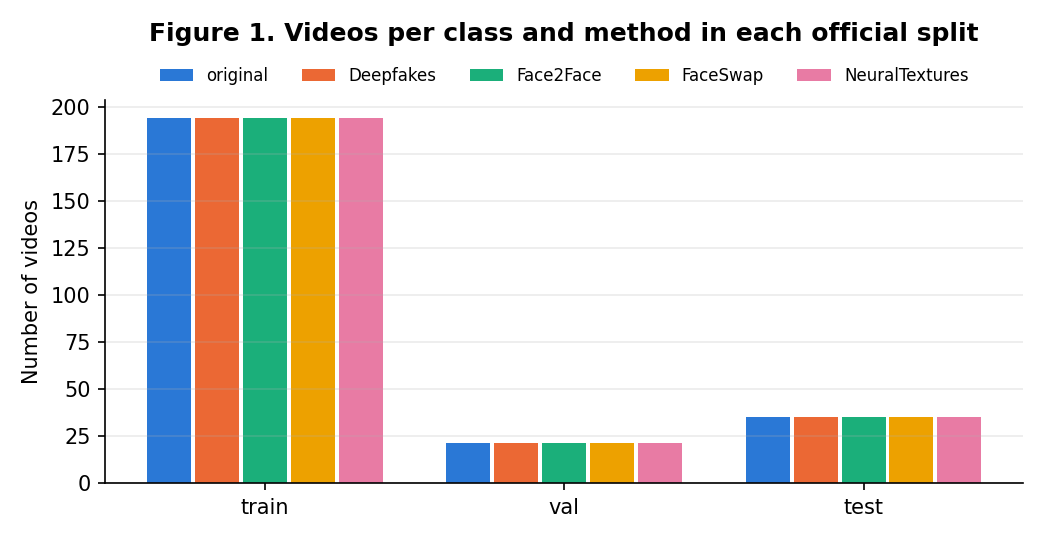

fig2_video_properties


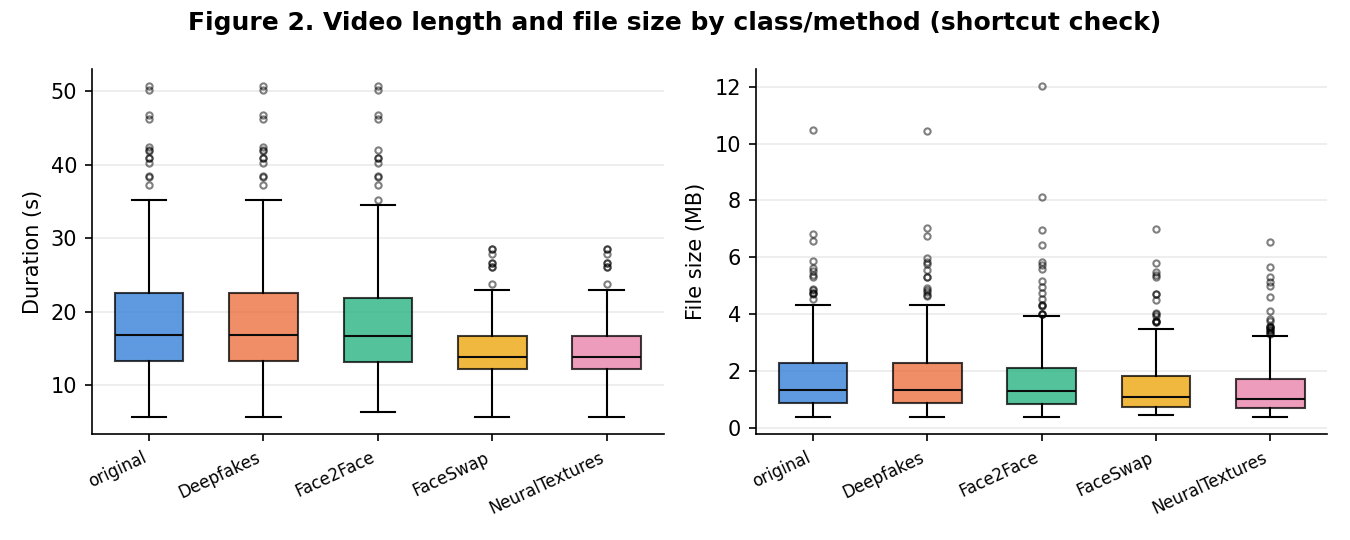

fig3_temporal_instability


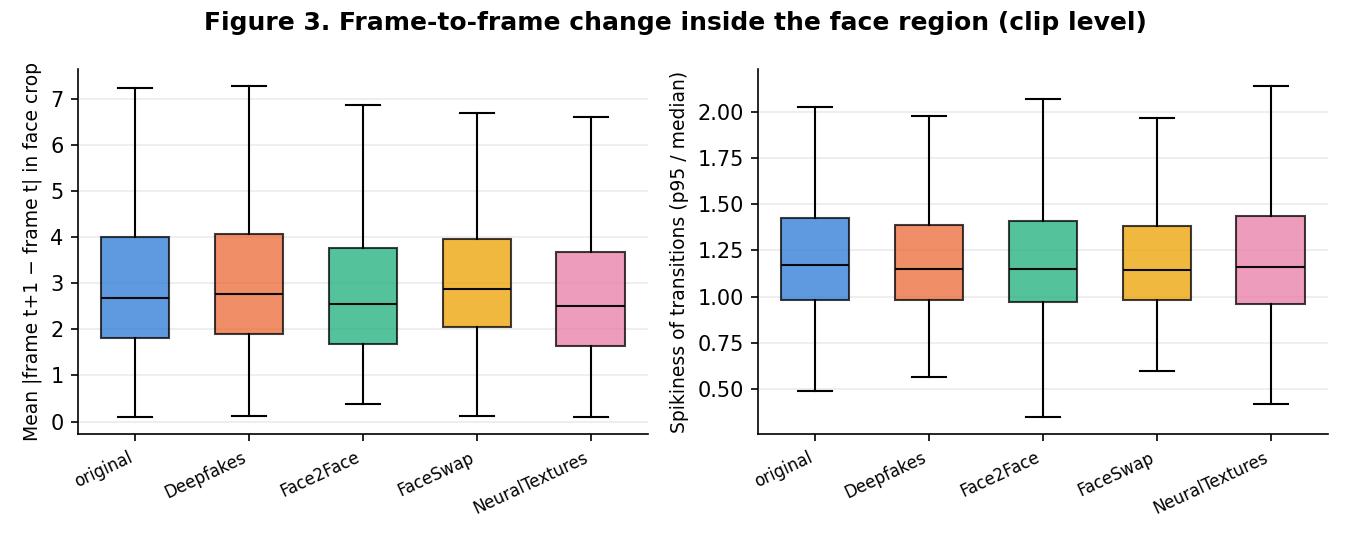

fig4_example_crops


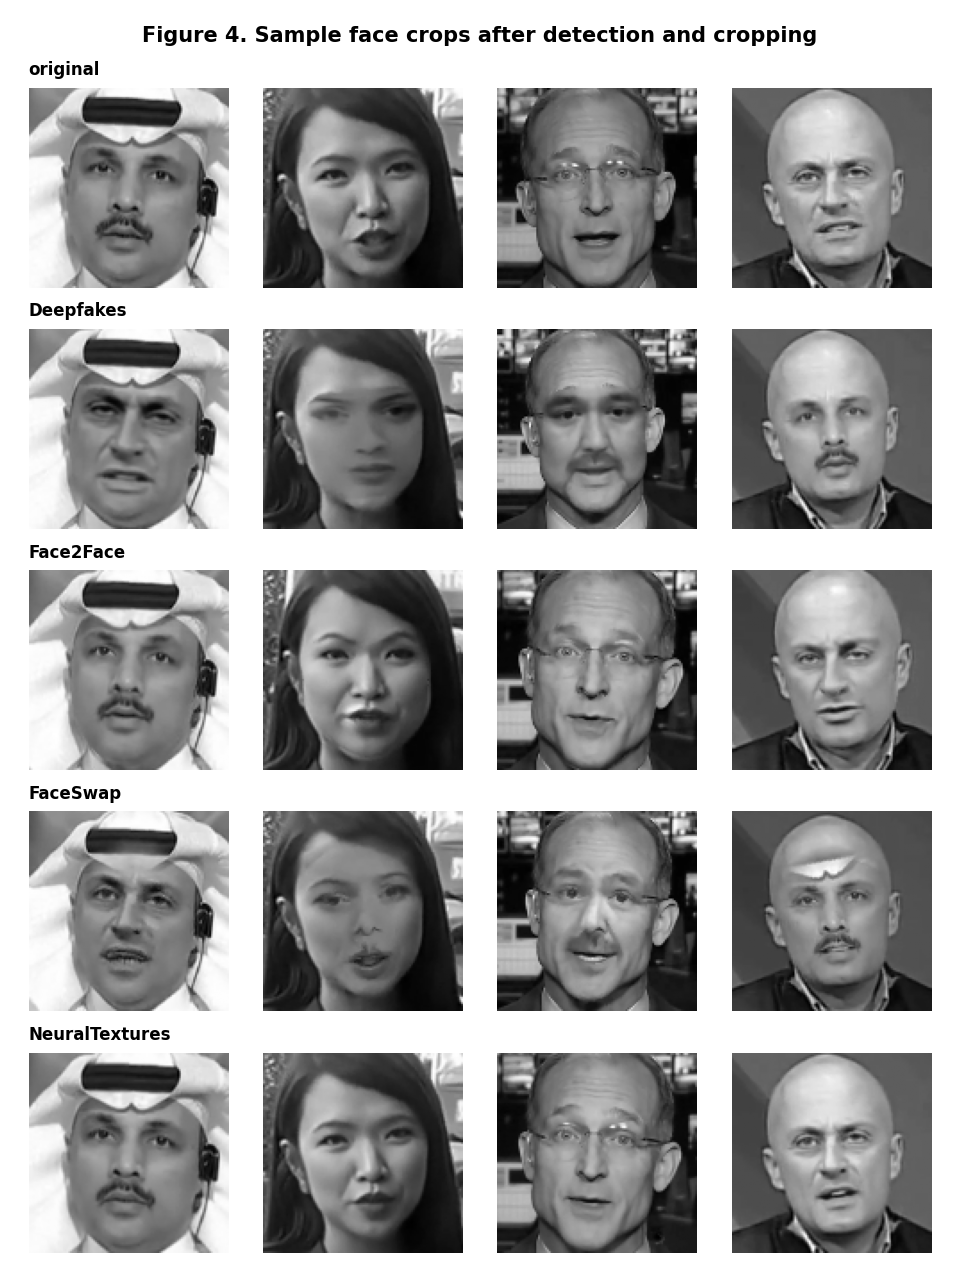

In [12]:
#@title 10 · Show the figures
from IPython.display import Image, display
for f in ["fig1_class_split", "fig2_video_properties", "fig3_temporal_instability", "fig4_example_crops"]:
    path = f"{OUT_DIR}/{f}.png"
    if os.path.exists(path):
        print(f); display(Image(path, width=750))

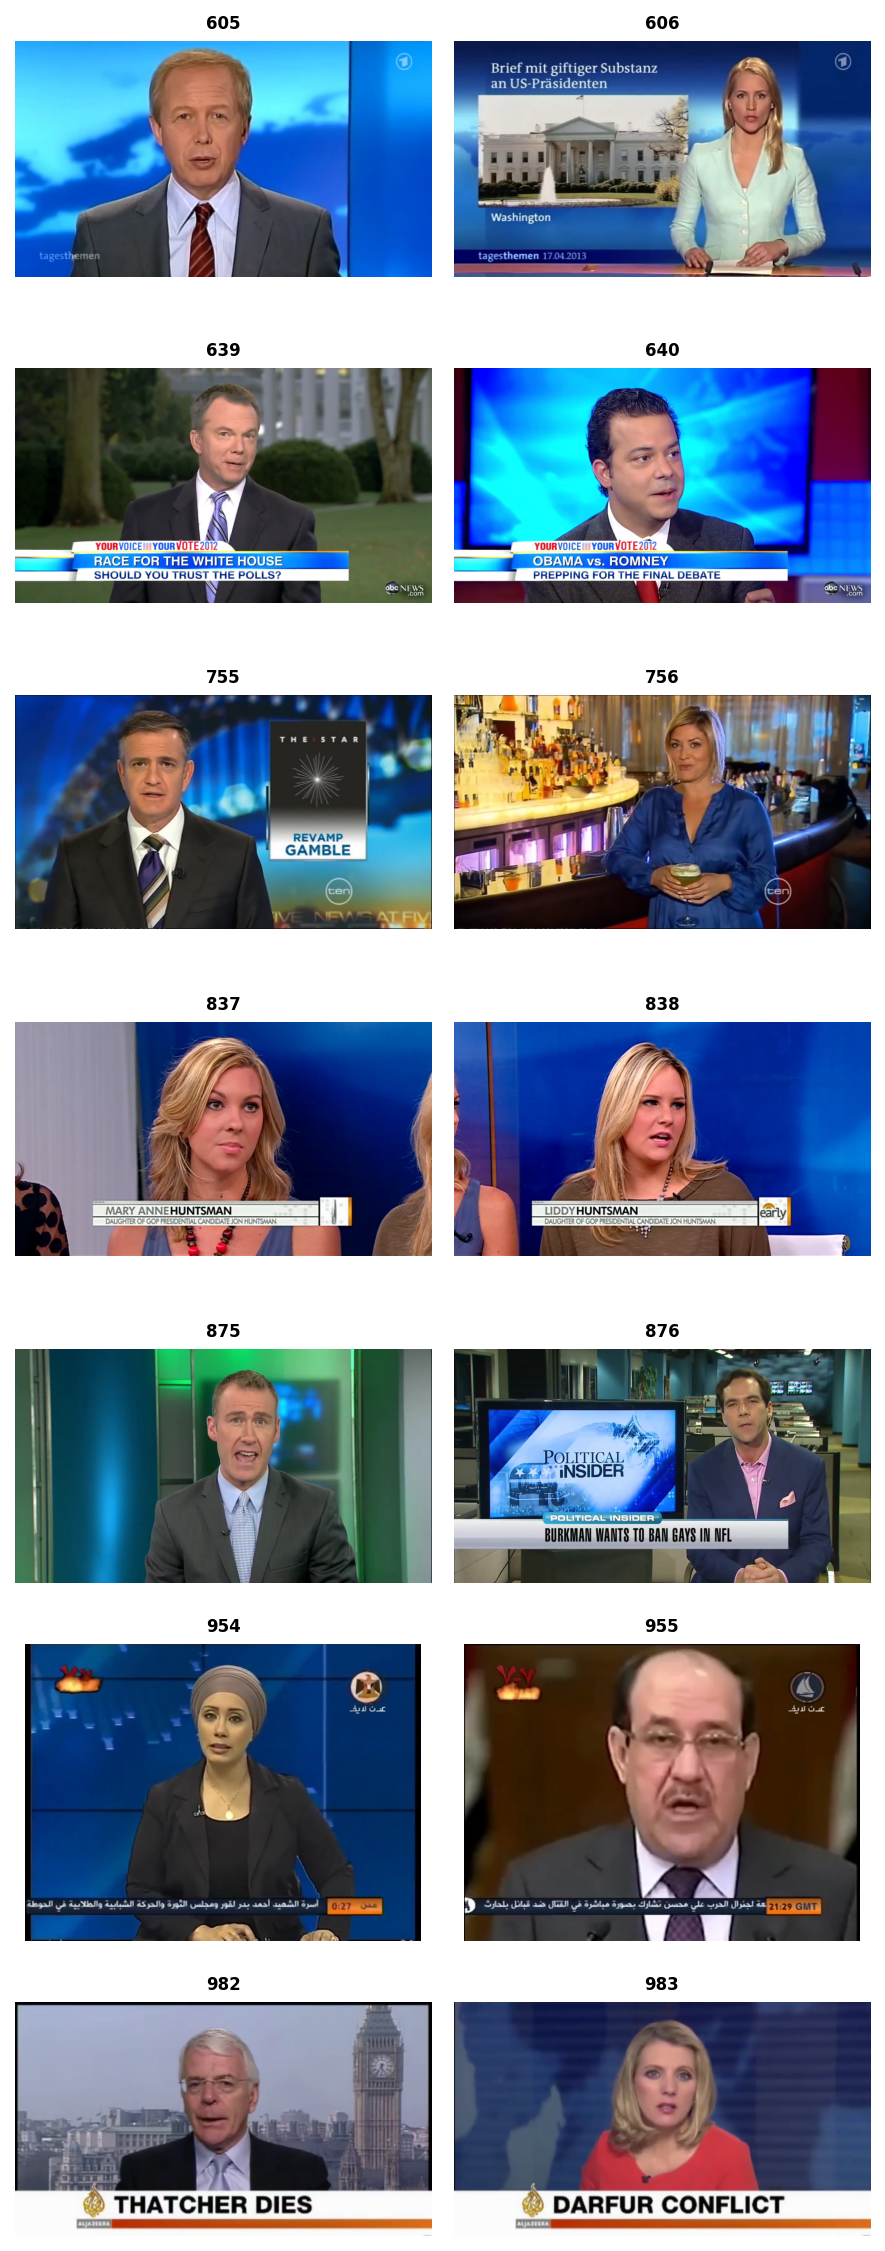

In [13]:
#@title 11 · Leakage check: are the 7 overlapping groups the same person?
%matplotlib inline
import matplotlib.pyplot as plt
GROUPS = [("605","606"), ("639","640"), ("755","756"), ("837","838"), ("875","876"), ("954","955"), ("982","983")]

def mid_frame(path):
    cap = cv2.VideoCapture(path); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, n // 2); ok, fr = cap.read(); cap.release()
    return cv2.cvtColor(fr, cv2.COLOR_BGR2RGB) if ok else None

fig, axes = plt.subplots(len(GROUPS), 2, figsize=(6, 2.2 * len(GROUPS)))
for r, (a, c) in enumerate(GROUPS):
    for k, vid in enumerate((a, c)):
        ax = axes[r, k]; ax.axis("off")
        p = VID.get(("original", vid))
        if p:
            ax.imshow(mid_frame(p)); ax.set_title(vid, fontsize=8)
        else:
            ax.set_title(f"{vid}: not available", fontsize=8)
plt.tight_layout(); plt.show()

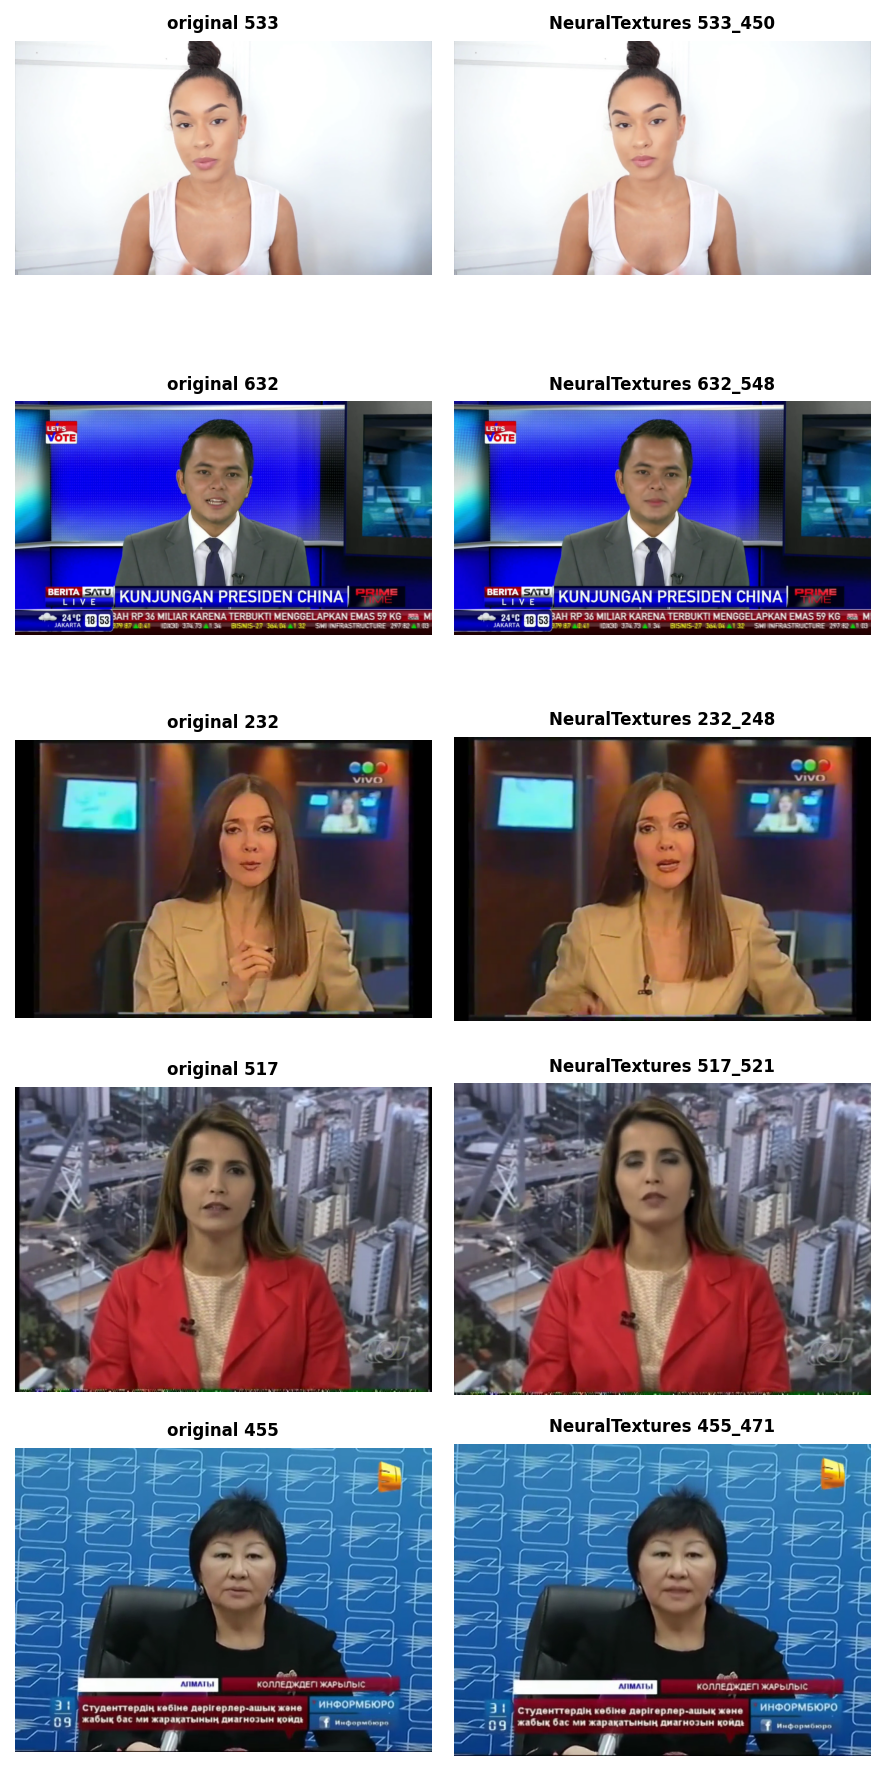

Note for each pair: is the manipulation visible? (clearly / barely / not visible)


In [14]:
#@title 12 · Label spot check: fake frame next to its original target
%matplotlib inline
import matplotlib.pyplot as plt
METHOD = "NeuralTextures"  #@param ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]
N_SHOW = 5  #@param {type:"integer"}
fakes = sorted(k[1] for k in VID if k[0] == METHOD)
random.seed(665)
pick = random.sample(fakes, min(N_SHOW, len(fakes)))
if not pick:
    print(f"No {METHOD} videos available.")
else:
    fig, axes = plt.subplots(len(pick), 2, figsize=(6, 2.4 * len(pick)), squeeze=False)
    for r, stem in enumerate(pick):
        target = stem.split("_")[0]
        for k, (p, t) in enumerate([(VID.get(("original", target)), f"original {target}"),
                                    (VID[(METHOD, stem)], f"{METHOD} {stem}")]):
            ax = axes[r, k]; ax.axis("off")
            if p:
                ax.imshow(mid_frame(p)); ax.set_title(t, fontsize=8)
    plt.tight_layout(); plt.show()
    print("Note for each pair: is the manipulation visible? (clearly / barely / not visible)")

In [15]:
!jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/FFpp_EDA_Colab-2.ipynb"

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/FFpp_EDA_Colab-2.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 6230885 bytes to /content/drive/MyDrive/Colab Notebooks/FFpp_EDA_Colab-2.html
